# Forelesning 6: Numerisk derivasjon (løsningsforslag)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Del 1: Fra grenseverdi til differanse

In [3]:
def forward(f, x, h=1e-8):
    return (f(x + h) - f(x)) / h

def g(x):
    return x**2 - 4*x + 5

print(forward(g, 1))   # analytisk: g'(x) = 2x - 4 = -2

-1.999999987845058


## Del 2: Er mindre steg alltid bedre?

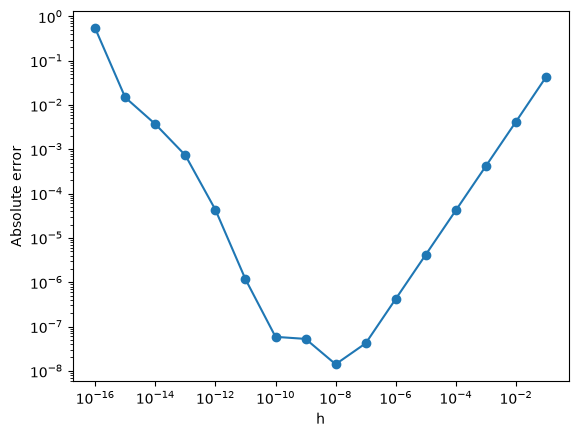

In [4]:
h_values = np.logspace(-1, -16, 16)
errors = []

for h in h_values:
    error = abs(forward(np.sin, 1, h) - np.cos(1))
    errors.append(error)

plt.loglog(h_values, errors, "o-")
plt.xlabel("h")
plt.ylabel("Absolute error")
plt.show()

## Del 3: Bakover- og sentraldifferanse

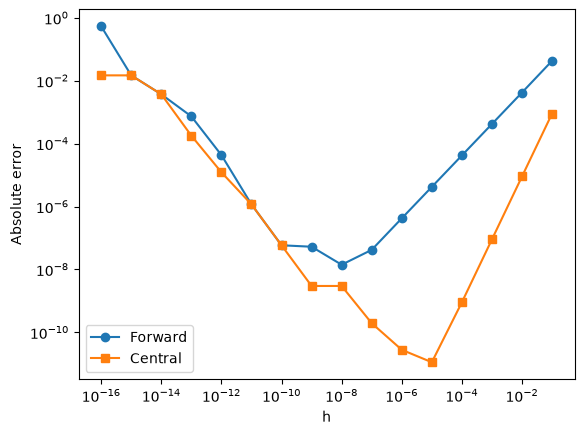

In [5]:
def central(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2*h)

errors_central = []
for h in h_values:
    errors_central.append(abs(central(np.sin, 1, h) - np.cos(1)))

plt.loglog(h_values, errors, "o-", label="Forward")
plt.loglog(h_values, errors_central, "s-", label="Central")
plt.xlabel("h")
plt.ylabel("Absolute error")
plt.legend()
plt.show()

## Del 4: Derivasjon av måledata

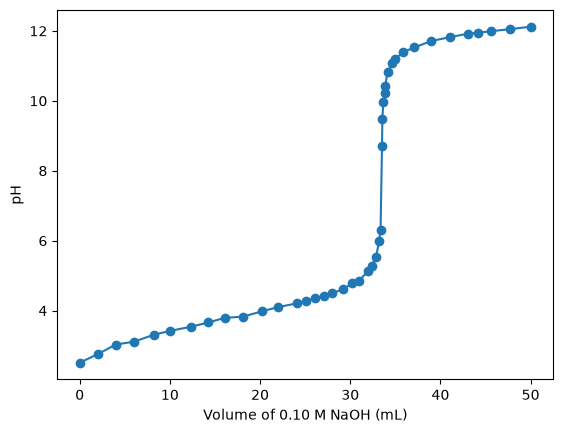

In [6]:
data = pd.read_csv("../datafiler/titreringsdata.txt")
volume = data["volum"].to_numpy()
pH = data["pH"].to_numpy()

plt.plot(volume, pH, "o-")
plt.xlabel("Volume of 0.10 M NaOH (mL)")
plt.ylabel("pH")
plt.show()

Equivalence point: 33.54 mL


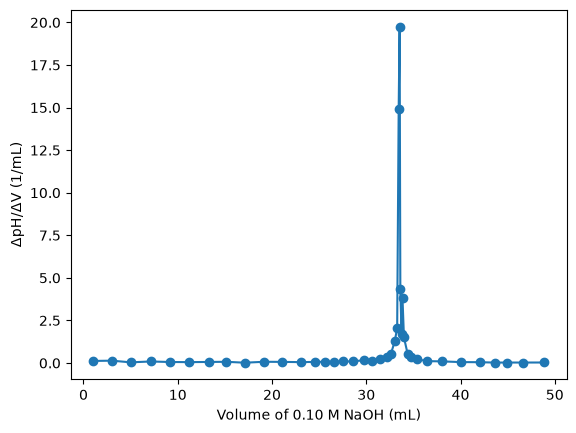

In [7]:
dpH_dV = np.diff(pH) / np.diff(volume)
volume_der = (volume[:-1] + volume[1:]) / 2   # midtpunktet i hvert intervall

V_eq = volume_der[np.argmax(dpH_dV)]
print(f"Equivalence point: {V_eq:.2f} mL")

plt.plot(volume_der, dpH_dV, "o-")
plt.xlabel("Volume of 0.10 M NaOH (mL)")
plt.ylabel("ΔpH/ΔV (1/mL)")
plt.show()

### `np.gradient`

In [8]:
dpH_dV_gradient = np.gradient(pH, volume)
print(f"Equivalence point: {volume[np.argmax(dpH_dV_gradient)]:.2f} mL")

Equivalence point: 33.52 mL


## Del 5: Alt er tall

### Derivasjon av lyd

In [9]:
from scipy.io import wavfile
from IPython.display import Audio

rate, sound = wavfile.read("../datafiler/lyd.wav")
print(len(sound), rate)
Audio(sound, rate=rate)

287973 44100


In [14]:
Audio(np.diff(sound), rate=rate)

### Derivasjon av bilder

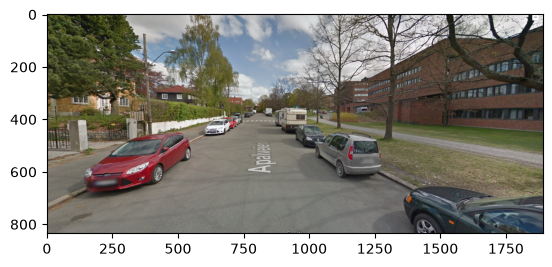

In [15]:
img = plt.imread("../datafiler/kjemibygningen.jpg")
plt.imshow(img)
plt.show()

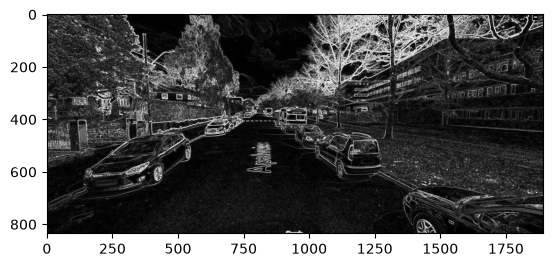

In [16]:
gray = np.mean(img, axis=2)

dy, dx = np.gradient(gray)
edges = np.abs(dx) + np.abs(dy)

plt.imshow(edges, cmap="gray", vmax=60)
plt.show()

## Oppgaver

### Oppgave 1

In [ ]:
print(central(np.exp, 2), np.exp(2))

def f(x):
    return np.sqrt(np.log(x))

print(central(f, 2), 1 / (2 * 2 * np.sqrt(np.log(2))))

### Oppgave 2

In [ ]:
t = np.array([0, 10, 20, 30, 40, 50])
c = np.array([1.00, 0.82, 0.68, 0.56, 0.47, 0.40])

rate = -np.diff(c) / np.diff(t)
t_mid = (t[:-1] + t[1:]) / 2

plt.plot(t_mid, rate, "o-")
plt.xlabel("Time (s)")
plt.ylabel("Rate (mol/(L s))")
plt.show()

### Oppgave 3

In [ ]:
def U(r):
    return r**-12 - 2 * r**-6

r = np.linspace(0.9, 2.0, 1101)
dU_dr = central(U, r)
print(f"dU/dr = 0 at r = {r[np.argmin(np.abs(dU_dr))]:.3f}")

plt.plot(r, U(r))
plt.xlabel("r")
plt.ylabel("U(r)")
plt.show()

### Oppgave 4

In [ ]:
C = 0.010
Ka = 1.75e-5
Kw = 1.0e-14

def charge_balance(h):
    return h - C * Ka / (h + Ka) - Kw / h

for step in [1e-8, 1e-5, 3e-4]:
    h = np.sqrt(Ka * C)
    i = 0
    while abs(charge_balance(h)) > 1e-12 and i < 50:
        h = h - charge_balance(h) / central(charge_balance, h, step)
        i = i + 1
    print(f"step = {step}   pH = {-np.log10(h):.3f}   iterations = {i}")

### Oppgave 5

In [ ]:
t = np.sort(np.random.default_rng(1).uniform(0, 10, 20))
y = np.sin(t)

wrong = np.gradient(y, t[1] - t[0])
right = np.gradient(y, t)

plt.plot(t, np.cos(t), label="Exact")
plt.plot(t, wrong, "o", label="Constant Δt (wrong)")
plt.plot(t, right, "s", label="np.gradient(y, t)")
plt.legend()
plt.show()

### Oppgave 6

In [ ]:
img = plt.imread("../datafiler/sommerfugl.jpg")
gray = np.mean(img, axis=2)
dy, dx = np.gradient(gray)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(np.abs(dx), cmap="gray", vmax=60)
axes[0].set_title("x-direction")
axes[1].imshow(np.abs(dy), cmap="gray", vmax=60)
axes[1].set_title("y-direction")
plt.show()